In [1]:
import gensim
import os
import gensim.downloader as api

In [2]:
# Manual workaround - download and load text8 manually
import urllib.request
import os
import gensim

# Download text8 manually
url = "http://mattmahoney.net/dc/text8.zip"
zip_path = "text8.zip"

if not os.path.exists(zip_path):
    print("Downloading text8...")
    urllib.request.urlretrieve(url, zip_path)
    print("Download complete!")

# Extract it
import zipfile
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('.')
    print("Extracted!")

# Load the text
with open('text8', 'r') as f:
    text = f.read()

# Tokenize into sentences (simple word-level split like gensim does)
words = text.split()
print(f"Loaded {len(words)} words")

# Create word list (text8 is already tokenized)
dataset = [words[i:i+100] for i in range(0, len(words), 100)]
print(f"Created {len(dataset)} chunks")
print("First chunk:", dataset[0][:10])

Extracted!
Loaded 17005207 words
Created 170053 chunks
First chunk: ['anarchism', 'originated', 'as', 'a', 'term', 'of', 'abuse', 'first', 'used', 'against']


In [3]:
type(dataset)

list

In [4]:
# don't do this, the output will get stuck
# for x in dataset:
#   print(x)

In [5]:
i = 0

for x in dataset:
    print(x)
    i += 1

    if i > 10:
        break

['anarchism', 'originated', 'as', 'a', 'term', 'of', 'abuse', 'first', 'used', 'against', 'early', 'working', 'class', 'radicals', 'including', 'the', 'diggers', 'of', 'the', 'english', 'revolution', 'and', 'the', 'sans', 'culottes', 'of', 'the', 'french', 'revolution', 'whilst', 'the', 'term', 'is', 'still', 'used', 'in', 'a', 'pejorative', 'way', 'to', 'describe', 'any', 'act', 'that', 'used', 'violent', 'means', 'to', 'destroy', 'the', 'organization', 'of', 'society', 'it', 'has', 'also', 'been', 'taken', 'up', 'as', 'a', 'positive', 'label', 'by', 'self', 'defined', 'anarchists', 'the', 'word', 'anarchism', 'is', 'derived', 'from', 'the', 'greek', 'without', 'archons', 'ruler', 'chief', 'king', 'anarchism', 'as', 'a', 'political', 'philosophy', 'is', 'the', 'belief', 'that', 'rulers', 'are', 'unnecessary', 'and', 'should', 'be', 'abolished', 'although', 'there', 'are', 'differing']
['interpretations', 'of', 'what', 'this', 'means', 'anarchism', 'also', 'refers', 'to', 'related', 's

In [6]:
i = 0

for x in dataset:
    i += 1

print(i)

170053


In [7]:
doc_lengths = []

for x in dataset:
    l = len(x)
    doc_lengths.append(l)

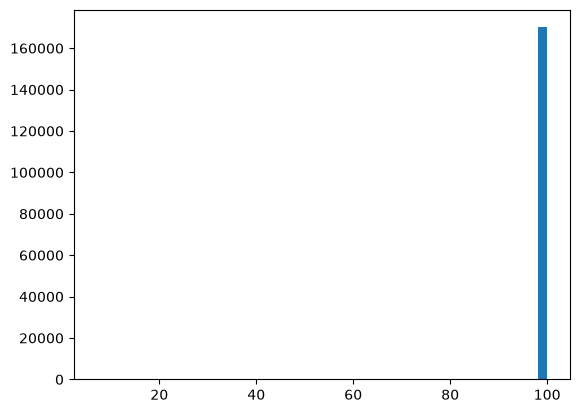

In [8]:
import matplotlib.pyplot as plt

plt.hist(doc_lengths, bins=50);

In [9]:
import numpy as np

np.mean(doc_lengths), np.std(doc_lengths)

(np.float64(99.99945311167694), np.float64(0.2255223158736603))

In [10]:
# build word2idx
from tensorflow.keras.preprocessing.text import Tokenizer

In [11]:
vocab_size = 20_000

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(dataset)

sequences = tokenizer.texts_to_sequences(dataset)

In [12]:
type(sequences)

list

In [13]:
type(sequences[0])

list

In [14]:
type(sequences[0][0])

int

In [15]:
len(sequences)

170053

In [16]:
len(sequences[0])

97

In [17]:
tokenizer.num_words

len(tokenizer.word_index)

tokenizer.word_index

tokenizer.index_word

{1: 'the',
 2: 'of',
 3: 'and',
 4: 'one',
 5: 'in',
 6: 'a',
 7: 'to',
 8: 'zero',
 9: 'nine',
 10: 'two',
 11: 'is',
 12: 'as',
 13: 'eight',
 14: 'for',
 15: 's',
 16: 'five',
 17: 'three',
 18: 'was',
 19: 'by',
 20: 'that',
 21: 'four',
 22: 'six',
 23: 'seven',
 24: 'with',
 25: 'on',
 26: 'are',
 27: 'it',
 28: 'from',
 29: 'or',
 30: 'his',
 31: 'an',
 32: 'be',
 33: 'this',
 34: 'which',
 35: 'at',
 36: 'he',
 37: 'also',
 38: 'not',
 39: 'have',
 40: 'were',
 41: 'has',
 42: 'but',
 43: 'other',
 44: 'their',
 45: 'its',
 46: 'first',
 47: 'they',
 48: 'some',
 49: 'had',
 50: 'all',
 51: 'more',
 52: 'most',
 53: 'can',
 54: 'been',
 55: 'such',
 56: 'many',
 57: 'who',
 58: 'new',
 59: 'used',
 60: 'there',
 61: 'after',
 62: 'when',
 63: 'into',
 64: 'american',
 65: 'time',
 66: 'these',
 67: 'only',
 68: 'see',
 69: 'may',
 70: 'than',
 71: 'world',
 72: 'i',
 73: 'b',
 74: 'would',
 75: 'd',
 76: 'no',
 77: 'however',
 78: 'between',
 79: 'about',
 80: 'over',
 81: 'yea

In [18]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.layers import Dense, Input, Embedding, Lambda
from tensorflow.keras.models import Model

In [19]:
import random
random.seed(1)
np.random.seed(1)
tf.random.set_seed(1)

In [20]:
# CBOW with negative sampling: predict the center word among sampled candidates.
context_size = 10
embedding_dim = 100
num_negative_samples = 10

context_input = Input(shape=(context_size,), dtype='int32', name='context')
candidate_input = Input(shape=(num_negative_samples + 1,), dtype='int32', name='candidates')

context_embedding_layer = Embedding(vocab_size, embedding_dim, name='context_embedding')
target_embedding_layer = Embedding(vocab_size, embedding_dim, name='target_embedding')

context_vectors = context_embedding_layer(context_input)
context_vector = Lambda(lambda t: tf.reduce_mean(t, axis=1))(context_vectors)
candidate_vectors = target_embedding_layer(candidate_input)
scores = Lambda(
    lambda tensors: tf.reduce_sum(tensors[0][:, tf.newaxis, :] * tensors[1], axis=-1)
)([context_vector, candidate_vectors])
output = tf.keras.layers.Activation('sigmoid')(scores)

model = Model([context_input, candidate_input], output)

In [21]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ context (InputLayer)          │ (None, 10)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ context_embedding (Embedding) │ (None, 10, 100)           │       2,000,000 │ context[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ candidates (InputLayer)       │ (None, 11)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lambda (Lambda)               │ (None, 100)               │               0 │ context_embedding[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ target_embedding (Embedding)  │ (None, 11, 100)           │       2,000,000 │ candidates[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lambda_1 (Lambda)             │ (None, 11)                │               0 │ lambda[0][0],              │
│                               │                           │                 │ target_embedding[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 11)                │               0 │ lambda_1[0][0]             │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 4,000,000 (15.26 MB)

 Trainable params: 4,000,000 (15.26 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
half_context_size = context_size // 2

# Join the tokenized chunks so training windows can cross former chunk boundaries.
tokens = np.concatenate(sequences).astype('int32')

# Draw negative words using the standard unigram^0.75 distribution.
word_counts = np.bincount(tokens, minlength=vocab_size).astype('float64')
negative_probs = word_counts ** 0.75
negative_probs[0] = 0
negative_probs /= negative_probs.sum()


def data_generator(tokens, batch_size=1024):
    offsets = np.concatenate((np.arange(-half_context_size, 0),
                              np.arange(1, half_context_size + 1)))
    centers = np.arange(half_context_size, len(tokens) - half_context_size,
                        dtype='int32')

    while True:
        # Every valid word position is used once per generator epoch.
        np.random.shuffle(centers)
        for start in range(0, len(centers), batch_size):
            batch_centers = centers[start:start + batch_size]
            contexts = tokens[batch_centers[:, None] + offsets[None, :]]
            targets = tokens[batch_centers]

            negatives = np.random.choice(
                vocab_size,
                size=(len(batch_centers), num_negative_samples),
                p=negative_probs
            ).astype('int32')
            collisions = negatives == targets[:, None]
            while collisions.any():
                negatives[collisions] = np.random.choice(
                    vocab_size, size=int(collisions.sum()), p=negative_probs
                )
                collisions = negatives == targets[:, None]

            candidates = np.concatenate((targets[:, None], negatives), axis=1)
            labels = np.zeros(candidates.shape, dtype='float32')
            labels[:, 0] = 1.0
            yield (contexts, candidates), labels

In [23]:
model.compile(
    loss='binary_crossentropy',
    optimizer='adam'
)

In [24]:
import math

batch_size = 1024
steps_per_epoch = math.ceil((len(tokens) - 2 * half_context_size) / batch_size)

# One epoch now covers every valid center-word position in the corpus.
r = model.fit(
    data_generator(tokens, batch_size),
    epochs=5,
    steps_per_epoch=steps_per_epoch,
    verbose=1
)

C:\Users\Anupam Tiwari\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/5
15634/15634 ━━━━━━━━━━━━━━━━━━━━ 328s 21ms/step - loss: 0.2422
Epoch 2/5
15634/15634 ━━━━━━━━━━━━━━━━━━━━ 349s 22ms/step - loss: 0.2075
Epoch 3/5
15634/15634 ━━━━━━━━━━━━━━━━━━━━ 356s 23ms/step - loss: 0.1964
Epoch 4/5
15634/15634 ━━━━━━━━━━━━━━━━━━━━ 347s 22ms/step - loss: 0.1901
Epoch 5/5
15634/15634 ━━━━━━━━━━━━━━━━━━━━ 334s 21ms/step - loss: 0.1862


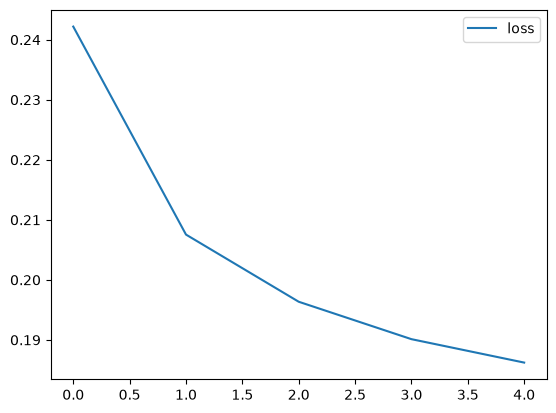

In [25]:
# Plot loss per iteration
plt.plot(r.history['loss'], label='loss')
plt.legend();

In [27]:
# Plot accuracy per iteration
plt.plot(r.history['accuracy'], label='acc')
plt.legend();

KeyError: 'accuracy'

In [28]:
# Average the input and output embeddings for word similarity tasks.
input_embeddings = model.get_layer('context_embedding').get_weights()[0]
target_embeddings = model.get_layer('target_embedding').get_weights()[0]
embeddings = (input_embeddings + target_embeddings) / 2
embeddings

array([[-0.00748696,  0.01323868,  0.03747181, ..., -0.02249027,
        -0.0011919 , -0.0211712 ],
       [-0.00630984, -0.06283584,  0.10237664, ...,  0.59364474,
         0.14729702,  0.2806565 ],
       [-0.15041277, -0.37696487,  0.18763535, ..., -0.05385853,
         0.21141627, -0.79051673],
       ...,
       [-0.30332297,  0.40123835,  0.40494993, ..., -0.6680831 ,
         0.39202255, -0.7088518 ],
       [-0.8486598 ,  0.34925   ,  0.72383237, ..., -0.9961079 ,
        -0.37822497, -0.39610493],
       [-0.26911238,  0.05155027, -0.29560107, ..., -0.82377243,
        -0.25355983, -0.4229477 ]], shape=(20000, 100), dtype=float32)

In [29]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5, algorithm='ball_tree')
neighbors.fit(embeddings)

,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'ball_tree'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'eu...an'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [30]:
queen_idx = tokenizer.word_index['queen']
queen = embeddings[queen_idx:queen_idx + 1]

distances, indices = neighbors.kneighbors(queen)

indices

array([[ 903, 2032, 3140, 3421,  879]])

In [31]:
for idx in indices[0]:
    word = tokenizer.index_word.get(int(idx), '<padding>')
    print(word)

queen
elizabeth
victoria
princess
mary


In [32]:
def print_neighbors(query):
    query_idx = tokenizer.word_index[query]
    query_embedding = embeddings[query_idx:query_idx + 1]

    distances, indices = neighbors.kneighbors(query_embedding)

    for idx in indices[0]:
        word = tokenizer.index_word.get(int(idx), '<padding>')
        print(word)

In [33]:
print_neighbors('paris')

paris
commune
fontainebleau
venice
sur


In [34]:
# king - man + woman ~= queen

def get_embedding(word):
    idx = tokenizer.word_index[word]
    return embeddings[idx:idx + 1]

king = get_embedding('king')
man = get_embedding('man')
woman = get_embedding('woman')

query = king - man + woman

distances, indices = neighbors.kneighbors(query)

for idx in indices[0]:
    word = tokenizer.index_word.get(int(idx), '<padding>')
    print(word)

king
queen
matilda
alexandra
daughter


In [35]:
# england - english + australian ~= australia

england = get_embedding('england')
english = get_embedding('english')
australian = get_embedding('australian')

query = england - english + australian

distances, indices = neighbors.kneighbors(query)

for idx in indices[0]:
    word = tokenizer.index_word.get(int(idx), '<padding>')
    print(word)

australia
melbourne
england
sydney
queensland


![](https://deeplearningcourses.com/notebooks_v3_pxl?sc=rNqZPzHeg0A0iHxXRZdjOA&n=CBOW+in+TF2)